# 환율 A2A 서버 & 클라이언트 테스트

https://github.com/a2aproject/a2a-samples/blob/main/samples/python/agents/langgraph/app/agent.py


# 세팅

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

In [33]:
!  pip install -U "a2a-sdk" 


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: C:\Users\jino7\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [29]:
! uv pip install --upgrade "protobuf>=5.29,<7"

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Resolved 1 package in 30ms
Audited 1 package in 0.54ms


# A2A 서버 실행

LangChain Agent & Tool 사용

## 서버 코드

In [ ]:
# rate_server.py
# A2A Protocol v1.0 (a2a-sdk 1.x) 서버 + LangChain 에이전트 연결

import uvicorn
from starlette.applications import Starlette

from a2a.helpers import new_text_message
from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import create_agent_card_routes, create_jsonrpc_routes
from a2a.server.tasks import InMemoryTaskStore
from a2a.types import AgentCapabilities, AgentCard, AgentInterface, AgentSkill
from a2a.utils.errors import UnsupportedOperationError

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver

# .env 파일의 환경변수(OPENAI_API_KEY 등)를 프로세스 환경에 로드
load_dotenv()


@tool
def get_exchange_rate(currency_from: str, currency_to: str) -> str:
    """두 통화 간 환율을 조회한다."""
    # 실제 환율 API 대신 고정값을 반환하는 더미 구현
    return f"1 {currency_from} = 1350 {currency_to}"


# LangChain 에이전트 생성
# checkpointer를 지정하면 thread_id 단위로 메시지 히스토리가 저장되어 멀티턴 대화가 유지됨
lc_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[get_exchange_rate],
    system_prompt="너는 환율 전문 어시스턴트다.",
    checkpointer=InMemorySaver(),
)


class CurrencyAgentExecutor(AgentExecutor):
    """A2A 프로토콜 계층과 LangChain 에이전트를 연결하는 어댑터"""

    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        try:
            # context.get_user_input(): 요청 메시지의 모든 text Part를 하나의 문자열로 합쳐서 반환
            # context.context_id: A2A의 대화 식별자. 클라이언트가 보내지 않으면 서버가 자동 생성함
            # 이 값을 LangGraph thread_id로 넘겨 같은 대화의 히스토리를 이어감
            result = await lc_agent.ainvoke(
                {"messages": [{"role": "user", "content": context.get_user_input()}]},
                config={"configurable": {"thread_id": context.context_id}},
            )
            # BaseMessage.text: content가 문자열이든 컨텐츠 블록 리스트이든
            # text 타입만 뽑아 문자열로 정규화해주는 langchain-core 1.x의 property
            answer = result["messages"][-1].text

        except Exception as e:
            # 예외를 그대로 올리면 JSON-RPC 에러 응답이 되므로,
            # 정상 응답 메시지 본문에 오류 내용을 담아 클라이언트가 읽을 수 있게 함
            answer = f"에이전트 실행 중 오류가 발생했습니다: {type(e).__name__}: {e}"

        # v1.0의 message-only 스트림 규칙: Message를 정확히 한 번만 enqueue하고 종료
        # new_text_message는 role 기본값이 ROLE_AGENT이므로 별도 지정 불필요
        await event_queue.enqueue_event(new_text_message(answer))

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        # 작업 취소를 지원하지 않으므로 A2A 표준 에러로 응답
        raise UnsupportedOperationError()


# 에이전트 카드: 다른 에이전트가 이 서버의 능력을 발견하는 데 쓰는 메타데이터
agent_card = AgentCard(
    name="Currency Agent",
    description="LangChain 기반 환율 에이전트",
    version="1.0.0",
    # v1.0에서 AgentCard.url이 제거되고 supported_interfaces로 대체됨
    # protocol_binding에는 'JSONRPC' / 'HTTP+JSON' / 'GRPC'를 지정
    supported_interfaces=[
        AgentInterface(
            url="http://localhost:9999/",
            protocol_binding="JSONRPC",
            protocol_version="1.0",
        )
    ],
    default_input_modes=["text"],
    default_output_modes=["text"],
    # 실제 구현이 중간 이벤트를 발행하지 않으므로 streaming=False로 선언
    capabilities=AgentCapabilities(streaming=False, push_notifications=False),
    skills=[
        AgentSkill(
            id="currency_convert",
            name="Currency Conversion",
            description="환율 조회 및 통화 변환을 수행한다",
            tags=["finance", "currency"],
            examples=["1달러는 몇 원이야?"],
        )
    ],
)

# 요청 핸들러: 프로토콜 요청을 받아 executor를 호출하고 Task 상태를 저장
# v1.0부터 agent_card가 필수 인자
request_handler = DefaultRequestHandler(
    agent_executor=CurrencyAgentExecutor(),
    task_store=InMemoryTaskStore(),
    agent_card=agent_card,
)

# v1.0에서 A2AStarletteApplication이 제거되고 라우트 팩토리 방식으로 변경됨
# create_agent_card_routes: GET /.well-known/agent-card.json (card_url 기본값)
# create_jsonrpc_routes: POST / (rpc_url은 기본값이 없어 반드시 지정)
app = Starlette(
    routes=create_agent_card_routes(agent_card)
    + create_jsonrpc_routes(request_handler, "/")
)

if __name__ == "__main__":
    uvicorn.run(app, host="0.0.0.0", port=9999)

## 터미날에서 실행

에럿l

uv pip install --upgrade "protobuf>=5.29,<7"

uv add "protobuf>=5.29,<7"

In [ ]:
 python rate_server.py 

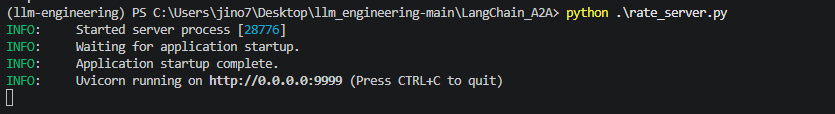

# A2A 클라이언트 구축

In [14]:
from uuid import uuid4

import httpx
from a2a.client import A2ACardResolver, ClientConfig, create_client
from a2a.helpers import get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

# 에이전트 카드를 조회할 베이스 URL
agent_url = "http://localhost:9999"

# 전송할 단일 메시지
user_input = "1달러는 몇 원이야?"

# 서버가 이 값을 LangGraph thread_id로 사용하므로 대화 식별자를 생성해 전달
context_id = uuid4().hex

# 카드 조회와 실제 요청에 공통으로 사용할 비동기 HTTP 클라이언트 생성
httpx_client = httpx.AsyncClient(timeout=180.0)

# 카드 리졸버를 만들어 서버에서 AgentCard를 다운로드 (기본 경로: /.well-known/agent-card.json)
agent_card = await A2ACardResolver(
    httpx_client=httpx_client, base_url=agent_url
).get_agent_card()

# 카드에 담긴 메타데이터를 출력
# 삼중 따옴표 첫 줄의 개행이 원본의 "\n에이전트 정보:"에서 앞부분 \n 역할을 함
print(f"""
에이전트 정보:
   - 이름: {agent_card.name}
   - 설명: {agent_card.description}
   - 버전: {agent_card.version}
   - 스킬 개수: {len(agent_card.skills)}""")

# 스킬 목록을 순회하며 이름/설명/예시를 출력
# 스킬이 없으면 헤더 자체를 출력하지 않도록 가드를 유지
if agent_card.skills:
    print("\n   스킬 목록:")
    for skill in agent_card.skills:
        print(f"   • {skill.name}: {skill.description}")
        if skill.examples:
            print(f"     예시: {', '.join(skill.examples[:3])}")

# 카드 정보를 기반으로 클라이언트 생성 (supported_interfaces를 보고 전송 바인딩을 자동 선택)
# streaming=False는 카드의 capabilities와 맞추고, 위에서 만든 httpx 클라이언트를 전송 계층에 주입
client = await create_client(
    agent_card, ClientConfig(streaming=False, httpx_client=httpx_client)
)

print(f"\n👤 사용자: {user_input}")

# 사용자 메시지 생성 후 요청 객체로 감쌈 (JSON-RPC 봉투는 SDK가 내부에서 처리)
# new_text_message가 text Part 생성과 message_id(uuid4) 부여를 함께 처리함
# role 기본값이 ROLE_AGENT이므로 사용자 메시지는 ROLE_USER를 명시해야 함
request = SendMessageRequest(
    message=new_text_message(user_input, context_id=context_id, role=Role.ROLE_USER)
)

# 응답은 StreamResponse의 비동기 이터레이터로 반환됨
# 대입 표현식으로 텍스트를 추출하면서 빈 값이면 건너뜀
async for response in client.send_message(request):
    if text := get_stream_response_text(response):
        print(f"🤖 에이전트: {text}")

# 연결 종료
await client.close()
await httpx_client.aclose()


에이전트 정보:
   - 이름: Currency Agent
   - 설명: LangChain 기반 환율 에이전트
   - 버전: 1.0.0
   - 스킬 개수: 1

   스킬 목록:
   • Currency Conversion: 환율 조회 및 통화 변환을 수행한다
     예시: 1달러는 몇 원이야?

👤 사용자: 1달러는 몇 원이야?
🤖 에이전트: 현재 환율 기준으로 1달러(USD) = 약 1,350원(KRW)입니다. 환전 시 은행 수수료나 우대율에 따라 실제 수령액은 달라질 수 있어요. 다른 금액으로 계산해드릴까요? 언제 환전할 계획인지 알려주시면 실시간 시세도 확인해 드립니다.


# A2A 서버 LangCahin agent 연결

In [15]:
import httpx
from uuid import uuid4
from a2a.client import ClientConfig, create_client
from a2a.helpers import get_stream_response_text
from a2a.types import Message, Part, Role, SendMessageRequest
from langchain.tools import tool
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

A2A_BASE_URL = "http://localhost:9999"
CONTEXT_ID = uuid4().hex

In [16]:
# 추가 import: from a2a.helpers import get_stream_response_text, new_text_message
# 제거 가능 import: Message, Part  (uuid4는 CONTEXT_ID 때문에 유지)

@tool
async def currency_agent(query: str) -> str:
    """원격 A2A 환율 에이전트에게 질의하고 응답 텍스트를 반환한다. 환율 조회나 통화 변환 요청 시 사용한다."""
    # 툴 호출 1회 동안만 유지되는 HTTP 클라이언트를 생성
    async with httpx.AsyncClient(timeout=180.0) as http_client:
        # A2A_BASE_URL의 AgentCard를 조회해 그에 맞는 transport로 클라이언트를 생성
        client = await create_client(
            agent=A2A_BASE_URL,
            client_config=ClientConfig(streaming=False, httpx_client=http_client),
        )

        # 텍스트 단일 Part를 가진 사용자 메시지를 생성해 요청으로 감쌈
        request = SendMessageRequest(
            message=new_text_message(query, role=Role.ROLE_USER, context_id=CONTEXT_ID)
        )

        # StreamResponse를 순회하며 텍스트만 추출
        texts = [get_stream_response_text(r) async for r in client.send_message(request)]

    # 빈 문자열을 제외하고 줄바꿈으로 연결해 반환
    return "\n".join(filter(None, texts))

In [17]:
# @tool 데코레이터가 생성한 StructuredTool 객체를 에이전트 없이 직접 실행
# A2A 서버 연결과 응답 파싱만 단독으로 검증하는 용도
# ainvoke는 비동기 실행 메서드이며, 인자는 함수 파라미터명을 키로 하는 dict로 전달
# Jupyter(ipykernel)는 셀 최상위 await를 지원하므로 asyncio.run 없이 await를 직접 사용
result = await currency_agent.ainvoke({"query": "1달러는 몇 원이야?"})

# 툴이 반환한 문자열을 출력
print(result)

현재 기준으로 1달러(USD)는 약 1,350원(KRW)입니다.

예)
- 10 USD = 13,500 KRW
- 100 USD = 135,000 KRW

환율은 실시간으로 변동하고, 은행·환전소의 매매기준율이나 수수료가 적용되면 실제 환전액은 달라질 수 있습니다. 다른 금액을 환산해 드릴까요? 또는 매매기준율(매도/매수)도 알고 싶으신가요?


In [18]:
# OpenAI 채팅 모델 인스턴스를 생성
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

# currency_agent 툴을 등록한 에이전트를 생성
agent = create_agent(
    model=llm,
    tools=[currency_agent],
    system_prompt=(
        "너는 사용자의 요청을 처리하는 에이전트다. "
        "환율 조회나 통화 변환이 필요한 요청은 currency_agent 툴을 호출해 "
        "그 응답을 사용자에게 전달해라."
    ),
)

# 사용자 메시지를 전달해 에이전트를 실행
result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "1달러가 원화로 얼마인지 알려줘"}]}
)

# messages 리스트의 마지막 항목에서 content를 출력
print(result["messages"][-1].content)

현재 환율 기준: 1 USD = 1,350 KRW입니다.

계산해드릴 다른 금액이나 다른 통화가 필요하면 알려주세요.
